In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load Candy dataset
df = pd.read_csv('/candy.csv')

# Features & Target
X = df.drop(columns=['competitorname', 'chocolate'])
y = df['chocolate']

# Preprocessing
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42
)

# 1. Train separate SVC models with different kernels
kernels = ['linear', 'poly', 'rbf']
kernel_accs = {}
kernel_models = {}

for k in kernels:
    clf = SVC(kernel=k, C=1.0)
    clf.fit(X_train, y_train)
    acc = accuracy_score(y_test, clf.predict(X_test))
    kernel_accs[k] = acc
    kernel_models[k] = clf

# 2. Hyperparameter Tuning using GridSearchCV
param_grid = {'C': [0.1, 1, 10], 'gamma': [0.1, 1, 10]}
grid = GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_
best_acc = accuracy_score(y_test, best_model.predict(X_test))

print("Kernel Accuracies:", kernel_accs)
print("Best Params:", grid.best_params_)
print("Best Tuned Accuracy:", best_acc)

Kernel Accuracies: {'linear': 0.9615384615384616, 'poly': 0.8076923076923077, 'rbf': 0.9230769230769231}
Best Params: {'C': 1, 'gamma': 0.1}
Best Tuned Accuracy: 0.9615384615384616


Shape of dataset: (85, 13)

Column names:
Index(['competitorname', 'chocolate', 'fruity', 'caramel', 'peanutyalmondy',
       'nougat', 'crispedricewafer', 'hard', 'bar', 'pluribus', 'sugarpercent',
       'pricepercent', 'winpercent'],
      dtype='object')

Missing values:
competitorname      0
chocolate           0
fruity              0
caramel             0
peanutyalmondy      0
nougat              0
crispedricewafer    0
hard                0
bar                 0
pluribus            0
sugarpercent        0
pricepercent        0
winpercent          0
dtype: int64
Input shape: (85, 12)
Target shape: (85,)
   competitorname  fruity  caramel  peanutyalmondy  nougat  crispedricewafer  \
0               0       0        1               0       0                 1   
1               1       0        0               0       1                 0   
2              44       0        0               0       0                 0   
3              45       0        0               0       0     

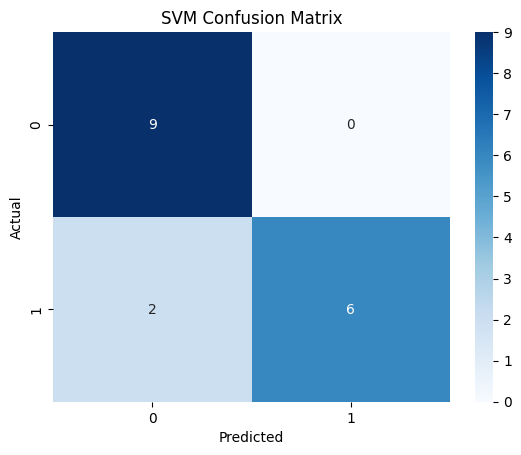

              precision    recall  f1-score   support

           0       0.82      1.00      0.90         9
           1       1.00      0.75      0.86         8

    accuracy                           0.88        17
   macro avg       0.91      0.88      0.88        17
weighted avg       0.90      0.88      0.88        17



In [ ]:
# Import required libraries

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Upload the CSV file
df = pd.read_csv('/candy.csv')
df.head()

# Display information about the dataset
print("Shape of dataset:", df.shape)
print("\nColumn names:")
print(df.columns)
print("\nMissing values:")
print(df.isnull().sum())

# Separate features and target
X = df.drop("chocolate", axis=1)
y = df["chocolate"]
print("Input shape:", X.shape)
print("Target shape:", y.shape)

# Encode categorical input features
encoder = LabelEncoder()
for column in X.columns:
    # Check if the column is of object type (string) before encoding
    if X[column].dtype == 'object':
        X[column] = encoder.fit_transform(X[column])

# Encode target variable
y = encoder.fit_transform(y)
print(X.head())
print(y[:10])

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

# Standardize the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Create SVM model using RBF kernel
model = SVC(kernel="rbf")

# Train the model
model.fit(X_train, y_train)

# Make predictions on test data
y_pred = model.predict(X_test)
print("Predicted values:")
print(y_pred[:20])

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)
print("Accuracy in percentage:", accuracy * 100, "%")

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

import matplotlib.pyplot as plt
import seaborn as sns
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM Confusion Matrix")
plt.show()

# Display classification report
print(classification_report(y_test, y_pred))